In [54]:
#EDA Notebook

#Imports  color schema, and Seeding
import os
import random
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image,ImageStat
from collections import Counter
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

random.seed(42)
np.random.seed(42)


In [ ]:
#Basic info on the dataset, class names and stuff like that


PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "data" / "raw" / "NSL"

IMAGE_EXTENSION = ".jpg"

BACKGROUND_CATEGORIES = [
    p.name for p in DATASET_DIR.iterdir()
    if p.is_dir()
]

CLASS_NAMES = sorted([
    p.name for p in (DATASET_DIR / BACKGROUND_CATEGORIES[0]).iterdir()
    if p.is_dir()
])


print("Number of classes:", len(CLASS_NAMES))
print("Classes:", CLASS_NAMES)


Number of classes: 36
Classes: ['0', '1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '4', '5', '6', '7', '8', '9']


In [44]:

structure_records = []

for background in BACKGROUND_CATEGORIES:

    background_dir = DATASET_DIR / background

    classes = sorted([
        p.name for p in background_dir.iterdir()
        if p.is_dir()
    ])

    missing_classes = sorted(set(CLASS_NAMES) - set(classes))
    additional_classes = sorted(set(classes) - set(CLASS_NAMES))

    structure_records.append({
        "Background": background,
        "Number of Classes": len(classes),
        "Missing Classes": missing_classes,
        "Additional Classes": additional_classes,
        "Structure Valid": (
            len(missing_classes) == 0
            and len(additional_classes) == 0
        )
    })

structure_df = pd.DataFrame(structure_records)

display(structure_df)


,Background,Number of Classes,Missing Classes,Additional Classes,Structure Valid
0,plain_background,36,[],[],True
1,random_background,36,[],[],True


In [45]:
records = []

for background in BACKGROUND_CATEGORIES:

    for class_name in CLASS_NAMES:

        class_dir = Path(f"{DATASET_DIR}//{background}//{class_name}")

        images = list(class_dir.glob("*.jpg"))

        records.append({
            "Background": background,
            "Class": class_name,
            "Image Count": len(images)
        })

dataset_df = pd.DataFrame(records)

display(dataset_df)

print("Total images:", dataset_df["Image Count"].sum())
print("Total classes:", len(CLASS_NAMES))
print("Background categories:", len(BACKGROUND_CATEGORIES))

,Background,Class,Image Count
0,plain_background,0,1000
1,plain_background,1,1000
2,plain_background,10,1000
3,plain_background,11,1000
4,plain_background,12,1000
...,...,...,...
67,random_background,5,500
68,random_background,6,500
69,random_background,7,500
70,random_background,8,500


Total images: 54000
Total classes: 36
Background categories: 2


,Image Count
Background,
plain_background,36000
random_background,18000


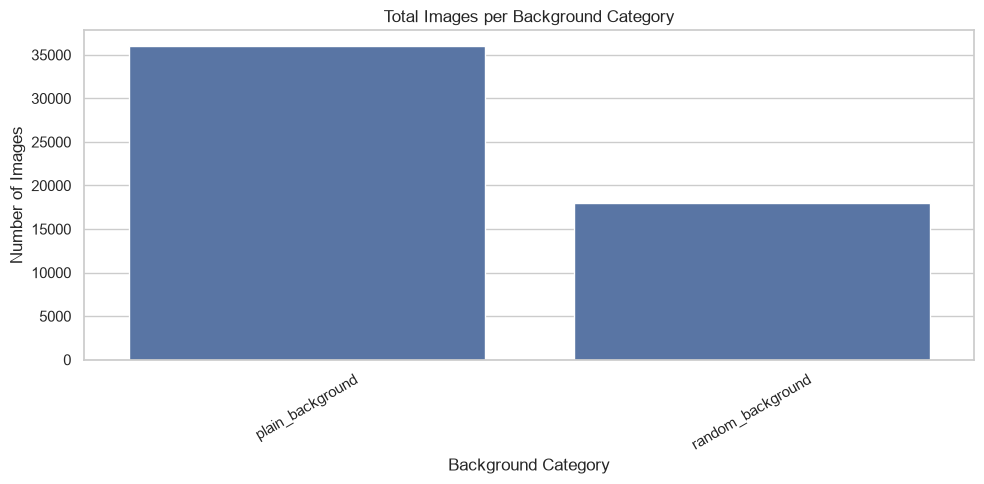

In [46]:

background_counts = (
    dataset_df.groupby("Background")["Image Count"]
    .sum()
    .sort_values(ascending=False)
)

display(background_counts.to_frame())

plt.figure(figsize=(10, 5))

sns.barplot(
    x=background_counts.index,
    y=background_counts.values
)

plt.title("Total Images per Background Category")
plt.xlabel("Background Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


,Image Count
Class,
0,1500
1,1500
10,1500
11,1500
12,1500
13,1500
14,1500
15,1500
16,1500


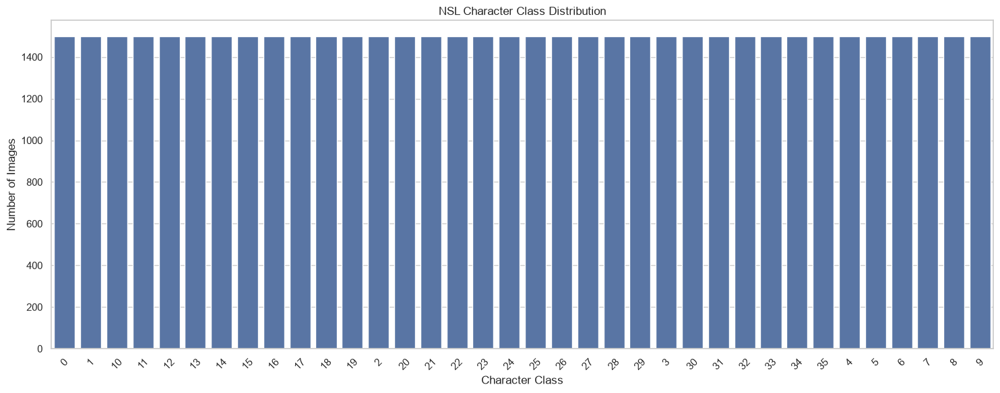

Maximum class count: 1500
Minimum class count: 1500
Average class count: 1500.0


In [47]:

class_counts = (
    dataset_df.groupby("Class")["Image Count"]
    .sum()
    .reindex(CLASS_NAMES, fill_value=0)
)

display(class_counts.to_frame("Image Count"))

plt.figure(figsize=(15, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("NSL Character Class Distribution")
plt.xlabel("Character Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Maximum class count:", class_counts.max())
print("Minimum class count:", class_counts.min())
print("Average class count:", round(class_counts.mean(), 2))


Background,plain_background,random_background
Class,,
0,1000,500
1,1000,500
10,1000,500
11,1000,500
12,1000,500
13,1000,500
14,1000,500
15,1000,500
16,1000,500


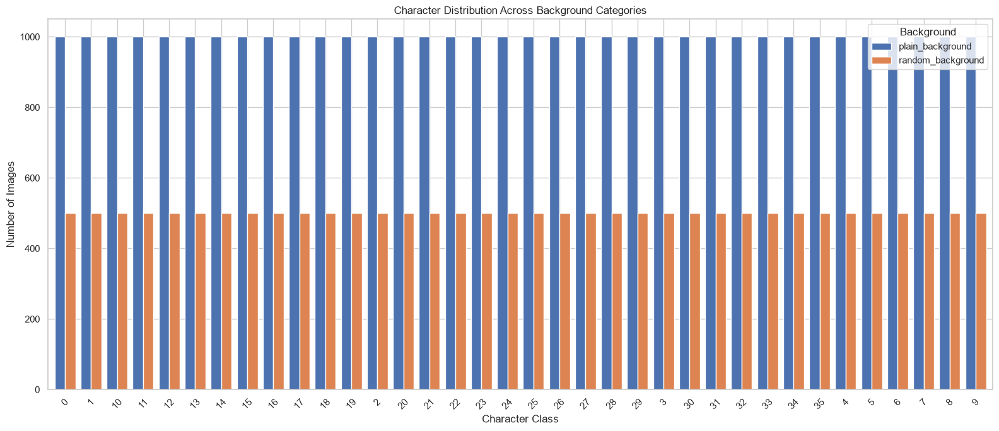

In [48]:

background_distribution = dataset_df.pivot(
    index="Class",
    columns="Background",
    values="Image Count"
).fillna(0)

display(background_distribution)

background_distribution.plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

plt.title("Character Distribution Across Background Categories")
plt.xlabel("Character Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.legend(title="Background")
plt.tight_layout()
plt.show()


In [55]:

image_records = []
corrupted_images = []

for background in BACKGROUND_CATEGORIES:

    for class_name in CLASS_NAMES:

        class_dir = DATASET_DIR / background / class_name

        for image_path in class_dir.glob("*.jpg"):

            try:
                with Image.open(image_path) as img:

                    width, height = img.size
                    image_format = img.format

                    grayscale = img.convert("L")
                    brightness = ImageStat.Stat(grayscale).mean[0]
                    contrast = ImageStat.Stat(grayscale).stddev[0]

                    img.verify()

                image_records.append({
                    "filename": image_path.name,
                    "background": background,
                    "class": class_name,
                    "width": width,
                    "height": height,
                    "resolution": width * height,
                    "aspect_ratio": width / height,
                    "file_size_kb": image_path.stat().st_size / 1024,
                    "brightness": brightness,
                    "contrast": contrast,
                    "format": image_format
                })

            except Exception as error:
                corrupted_images.append({
                    "path": str(image_path),
                    "error": str(error)
                })

images_df = pd.DataFrame(image_records)

print("Valid images:", len(images_df))
print("Corrupted images:", len(corrupted_images))

display(images_df.head())


Valid images: 54000
Corrupted images: 0


,filename,background,class,width,height,resolution,aspect_ratio,file_size_kb,brightness,contrast,format
0,0.jpg,plain_background,0,300,300,90000,1.0,11.789062,152.775567,34.012930,JPEG
1,1.jpg,plain_background,0,300,300,90000,1.0,11.999023,153.017656,34.187111,JPEG
2,10.jpg,plain_background,0,300,300,90000,1.0,11.134766,154.826933,24.437956,JPEG
3,100.jpg,plain_background,0,300,300,90000,1.0,14.093750,142.484367,39.045670,JPEG
4,101.jpg,plain_background,0,300,300,90000,1.0,11.621094,151.680400,28.641437,JPEG


In [56]:

dimension_stats = images_df[
    ["width", "height", "resolution"]
].describe()

display(dimension_stats)

print("Most common image dimensions:")

common_dimensions = (
    images_df.groupby(["width", "height"])
    .size()
    .reset_index(name="Image Count")
    .sort_values("Image Count", ascending=False)
)

display(common_dimensions.head(10))


,width,height,resolution
count,54000.0,54000.0,54000.0
mean,300.0,300.0,90000.0
std,0.0,0.0,0.0
min,300.0,300.0,90000.0
25%,300.0,300.0,90000.0
50%,300.0,300.0,90000.0
75%,300.0,300.0,90000.0
max,300.0,300.0,90000.0


Most common image dimensions:


,width,height,Image Count
0,300,300,54000


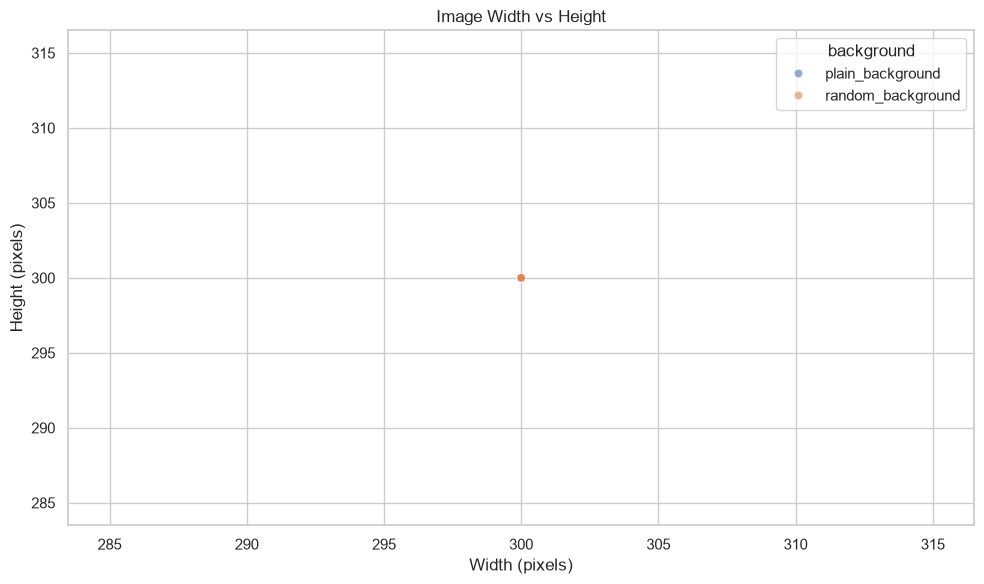

In [57]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=images_df,
    x="width",
    y="height",
    hue="background",
    alpha=0.6
)

plt.title("Image Width vs Height")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.tight_layout()
plt.show()


count    54000.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: aspect_ratio, dtype: float64

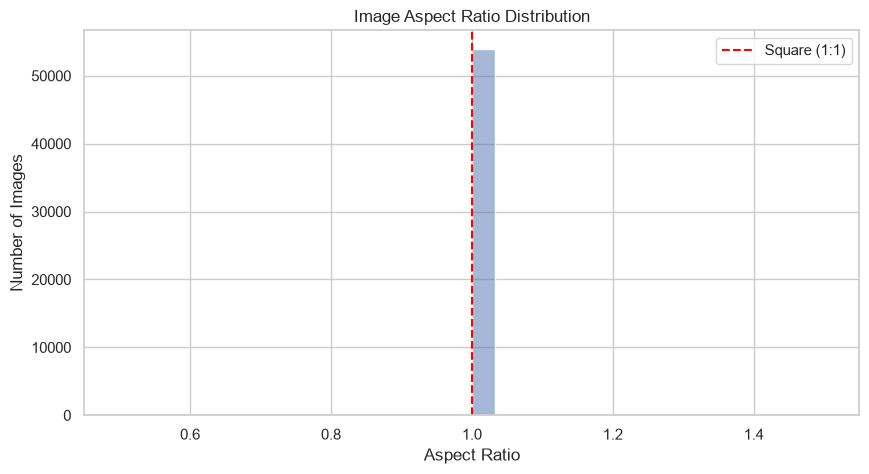

In [58]:

display(images_df["aspect_ratio"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=images_df,
    x="aspect_ratio",
    bins=30,
    kde=True
)

plt.axvline(
    1,
    color="red",
    linestyle="--",
    label="Square (1:1)"
)

plt.title("Image Aspect Ratio Distribution")
plt.xlabel("Aspect Ratio")
plt.ylabel("Number of Images")
plt.legend()
plt.show()


count    54000.000000
mean        18.855011
std          5.993127
min          8.755859
25%         14.656250
50%         17.236816
75%         20.498291
max         39.568359
Name: file_size_kb, dtype: float64

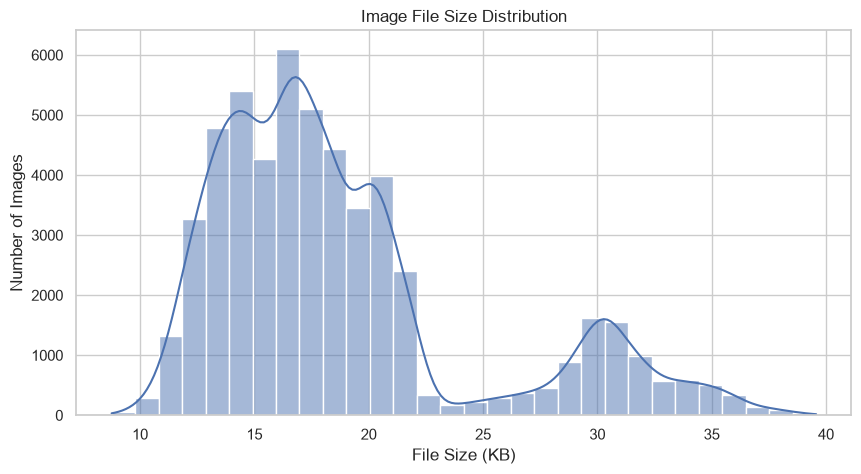

In [59]:

display(images_df["file_size_kb"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=images_df,
    x="file_size_kb",
    bins=30,
    kde=True
)

plt.title("Image File Size Distribution")
plt.xlabel("File Size (KB)")
plt.ylabel("Number of Images")
plt.show()


count    54000.000000
mean       176.880365
std         41.471544
min         77.224267
25%        141.431042
50%        171.112728
75%        209.554753
max        245.352822
Name: brightness, dtype: float64

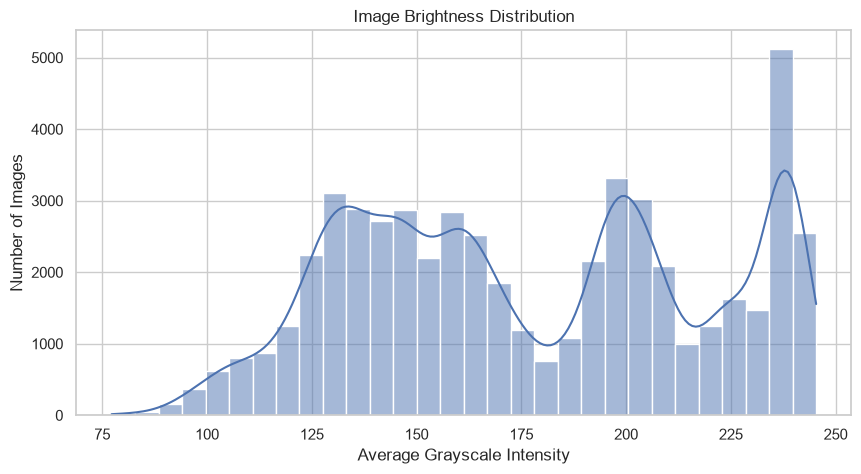

In [60]:

display(images_df["brightness"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=images_df,
    x="brightness",
    bins=30,
    kde=True
)

plt.title("Image Brightness Distribution")
plt.xlabel("Average Grayscale Intensity")
plt.ylabel("Number of Images")
plt.show()


count    54000.000000
mean        40.998819
std         14.652337
min         13.373458
25%         29.087782
50%         36.792320
75%         49.378893
max         91.574352
Name: contrast, dtype: float64

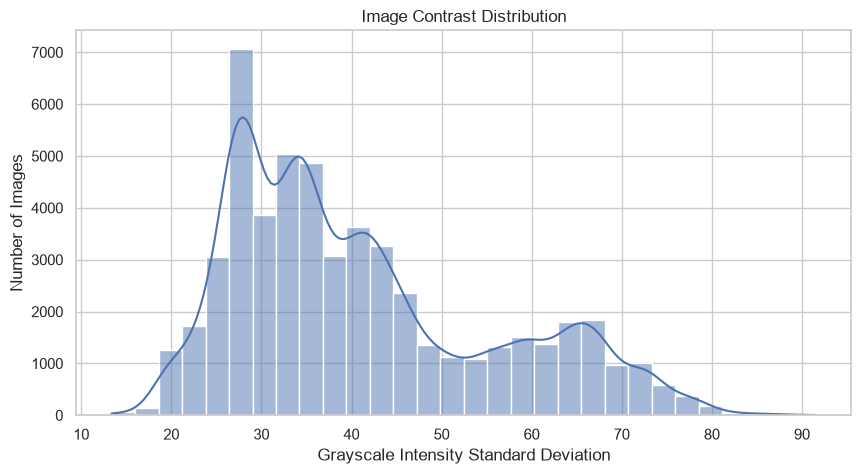

In [61]:

display(images_df["contrast"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=images_df,
    x="contrast",
    bins=30,
    kde=True
)

plt.title("Image Contrast Distribution")
plt.xlabel("Grayscale Intensity Standard Deviation")
plt.ylabel("Number of Images")
plt.show()


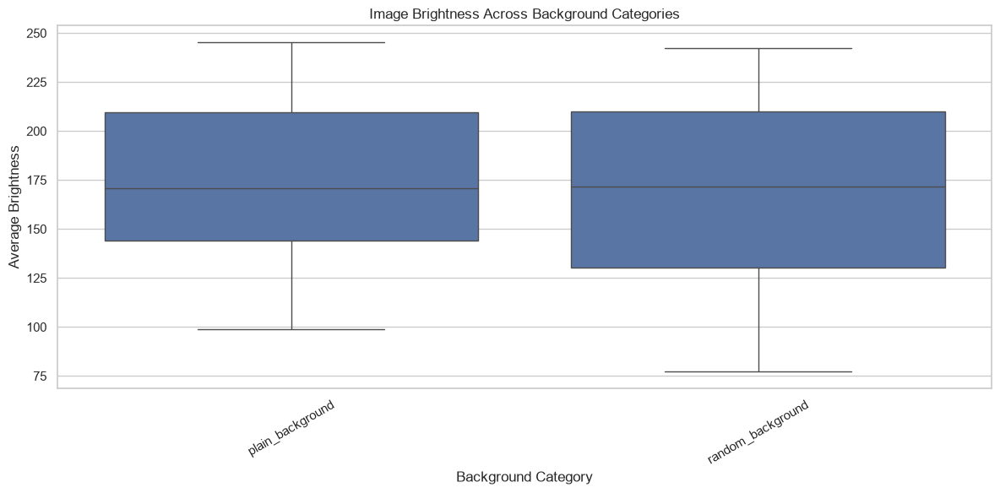

In [62]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=images_df,
    x="background",
    y="brightness"
)

plt.title("Image Brightness Across Background Categories")
plt.xlabel("Background Category")
plt.ylabel("Average Brightness")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


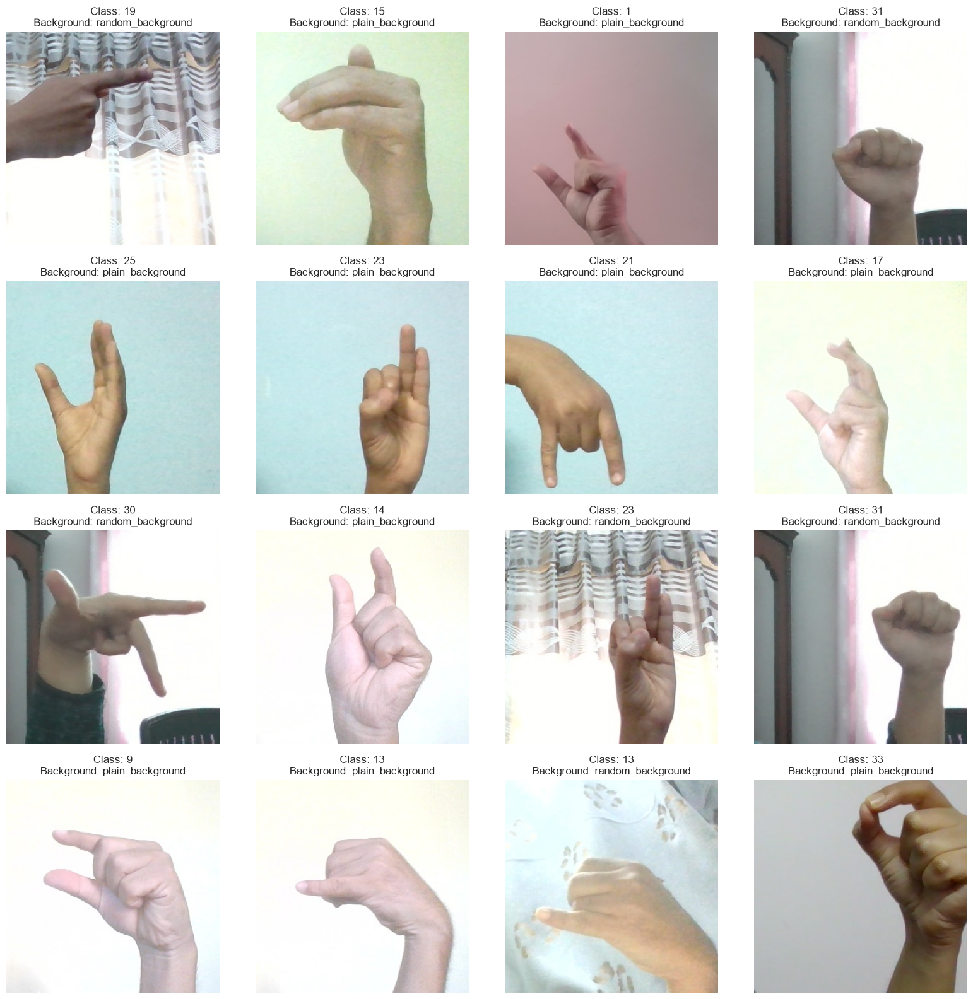

In [63]:

def visualize_random_samples(samples=16):

    image_paths = list(DATASET_DIR.rglob("*.jpg"))

    selected = random.sample(
        image_paths,
        min(samples, len(image_paths))
    )

    cols = 4
    rows = int(np.ceil(len(selected) / cols))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(16, rows * 4)
    )

    axes = np.array(axes).flatten()

    for ax, path in zip(axes, selected):

        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"Class: {path.parent.name}\n"
            f"Background: {path.parent.parent.name}"
        )

        ax.axis("off")

    for ax in axes[len(selected):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_random_samples(16)


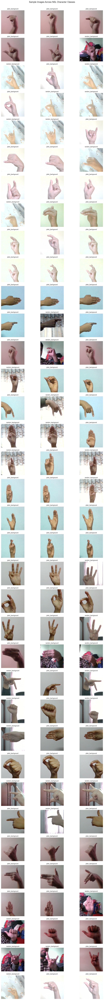

In [64]:

def visualize_classes(samples_per_class=3):

    fig, axes = plt.subplots(
        len(CLASS_NAMES),
        samples_per_class,
        figsize=(12, len(CLASS_NAMES) * 2.5)
    )

    for i, class_name in enumerate(CLASS_NAMES):

        class_images = []

        for background in BACKGROUND_CATEGORIES:

            class_dir = DATASET_DIR / background / class_name

            class_images.extend(list(class_dir.glob("*.jpg")))

        selected = random.sample(
            class_images,
            min(samples_per_class, len(class_images))
        )

        for j in range(samples_per_class):

            ax = axes[i, j]

            if j < len(selected):

                with Image.open(selected[j]) as img:
                    ax.imshow(img.convert("RGB"))

                ax.set_title(
                    selected[j].parent.parent.name,
                    fontsize=9
                )

            ax.axis("off")

            if j == 0:
                ax.set_ylabel(
                    f"Class {class_name}",
                    rotation=0,
                    labelpad=40
                )

    plt.suptitle(
        "Sample Images Across NSL Character Classes",
        y=1.001
    )

    plt.tight_layout()
    plt.show()


visualize_classes(samples_per_class=3)


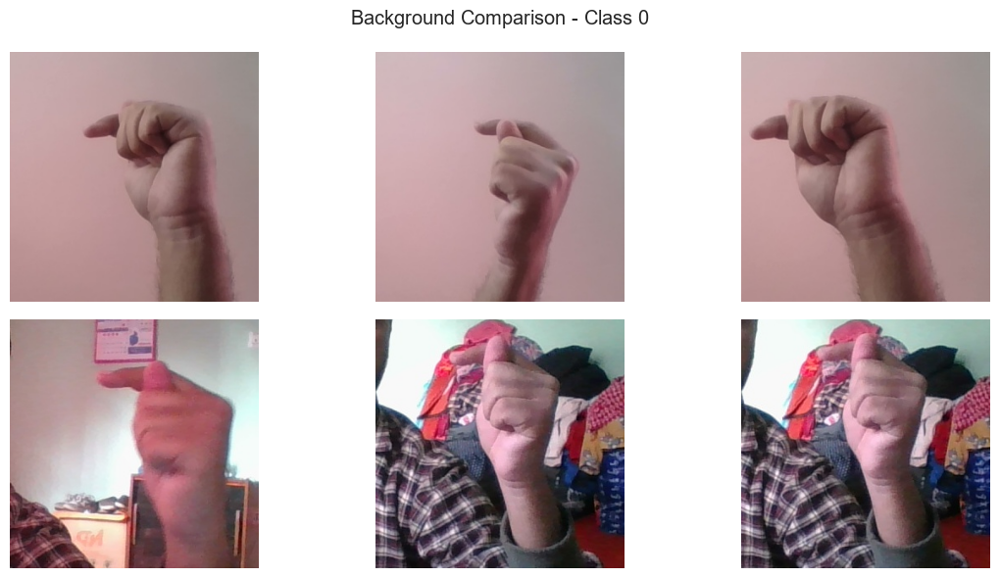

In [65]:

def compare_backgrounds(class_name, samples_per_background=3):

    fig, axes = plt.subplots(
        len(BACKGROUND_CATEGORIES),
        samples_per_background,
        figsize=(12, len(BACKGROUND_CATEGORIES) * 3)
    )

    if len(BACKGROUND_CATEGORIES) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, background in enumerate(BACKGROUND_CATEGORIES):

        class_dir = DATASET_DIR / background / class_name

        image_paths = list(class_dir.glob("*.jpg"))

        selected = random.sample(
            image_paths,
            min(samples_per_background, len(image_paths))
        )

        for j in range(samples_per_background):

            ax = axes[i, j]

            if j < len(selected):

                with Image.open(selected[j]) as img:
                    ax.imshow(img.convert("RGB"))

            ax.axis("off")

            if j == 0:
                ax.set_ylabel(
                    background,
                    rotation=0,
                    labelpad=60
                )

    plt.suptitle(f"Background Comparison - Class {class_name}")
    plt.tight_layout()
    plt.show()


# Change the class number to inspect another character
compare_backgrounds(CLASS_NAMES[0])


In [66]:

image_hashes = {}

for image_path in DATASET_DIR.rglob("*.jpg"):

    try:
        file_hash = hashlib.md5(
            image_path.read_bytes()
        ).hexdigest()

        image_hashes.setdefault(file_hash, []).append(
            str(image_path)
        )

    except Exception:
        continue

duplicates = {
    file_hash: paths
    for file_hash, paths in image_hashes.items()
    if len(paths) > 1
}

print("Total duplicate groups:", len(duplicates))

for file_hash, paths in list(duplicates.items())[:10]:

    print("\nHash:", file_hash)

    for path in paths:
        print(" ", path)


Total duplicate groups: 0


In [68]:

print("=" * 55)
print("       NEPALI SIGN LANGUAGE DATASET EDA")
print("=" * 55)

print("\nDATASET OVERVIEW")

print("Total images:", len(images_df))
print("Total character classes:", len(CLASS_NAMES))
print("Background categories:", len(BACKGROUND_CATEGORIES))

print("\nIMAGE DIMENSIONS")

print("Average width:", round(images_df["width"].mean(), 2))
print("Average height:", round(images_df["height"].mean(), 2))

print(
    "Most common resolution:",
    f"{common_dimensions.iloc[0]['width']} x "
    f"{common_dimensions.iloc[0]['height']}"
)

print("\nIMAGE FILE SIZE")

print(
    "Average file size:",
    round(images_df["file_size_kb"].mean(), 2),
    "KB"
)

print("\nCLASS DISTRIBUTION")

print("Largest class:", class_counts.idxmax())
print("Largest class count:", class_counts.max())

print("Smallest class:", class_counts.idxmin())
print("Smallest class count:", class_counts.min())

print("\nBACKGROUND DISTRIBUTION")

for background, count in background_counts.items():
    print(f"{background}: {count} images")

print("\nDATA QUALITY")

print("Corrupted images:", len(corrupted_images))
print("Duplicate image groups:", len(duplicates))
print("Empty class folders:", len(empty_classes))

print("\nSTRUCTURE VALID:", structure_df["Structure Valid"].all())

print("=" * 55)


       NEPALI SIGN LANGUAGE DATASET EDA

DATASET OVERVIEW
Total images: 54000
Total character classes: 36
Background categories: 2

IMAGE DIMENSIONS
Average width: 300.0
Average height: 300.0
Most common resolution: 300 x 300

IMAGE FILE SIZE
Average file size: 18.86 KB

CLASS DISTRIBUTION
Largest class: 0
Largest class count: 1500
Smallest class: 0
Smallest class count: 1500

BACKGROUND DISTRIBUTION
plain_background: 36000 images
random_background: 18000 images

DATA QUALITY
Corrupted images: 0
Duplicate image groups: 0
Empty class folders: 0

STRUCTURE VALID: True
